# **Práctica 5**

## **Resumen**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio                  
from scipy.signal import welch as pwelch

**4.1)** Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 
80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal, 
y utilice la frecuencia de muestreo necesaria para representarla apropiadamente.

- **Respuesta**

Frecuencia máxima de la señal (f_max): 160 Hz
Frecuencia de muestreo mínima teórica (Nyquist): 320 Hz


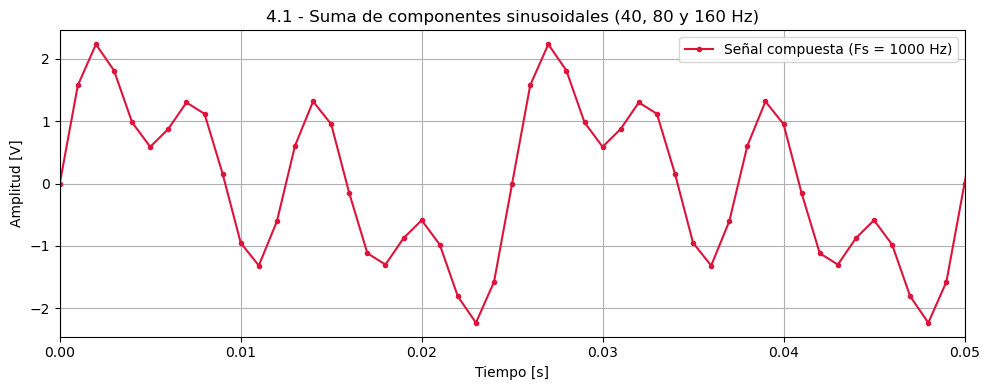

In [6]:
# Se definen las frecuencias de las tres componentes sinusoidales a usar en Hz
f1 = 40     
f2 = 80    
f3 = 160   #Frecuencia maxima de la señal 

#Se calcula la frecuencia de muestreo mínima según el Teorema de Nyquist-Shannon
# es el doble de la frecuencia máxima presente en la señal
Fs_min = 2 * f3
print(f"Frecuencia máxima de la señal (f_max): {f3} Hz")
print(f"Frecuencia de muestreo mínima teórica (Nyquist): {Fs_min} Hz")

# Sin embargo, se escoge una frecuencia de muestreo mayor, para que la señal 
#pueda verse bien representada en todas sus frecuencias

Fs = 1000         # Frecuencia de muestreo 
Ts = 1 / Fs       # Periodo de muestreo (intervalo de tiempo entre muestras, en segundos)

# Se defin el vector de tiempo
# Para esto se haya el periodo fundamental y este periodo existe si 
# sus frecuencias pueden expresarse como múltiplos enteros de una misma frecuencia fundamental.
# Por lo tanto, la frecuencia fundamental es el minimo comun divisor de 40, 80, 160. 
# la frecuencia fundamental es 40 y el periodo  fundamental Tp = 1/fp 
Tp = 1 / f1
t = np.arange(0, 10 * Tp, Ts)   # Genera 250 muestras equidistantes desde t = 0 hasta t = 0.249 s

# Se construye cada componente sinusoidal y suma total
x_40 = np.sin(2 * np.pi * f1 * t)    
x_80 = np.sin(2 * np.pi * f2 * t)    
x_160 = np.sin(2 * np.pi * f3 * t)   
signal = x_40 + x_80 + x_160         # Señal compuesta en el dominio del tiempo

# Se ggrafica la señal compuesta (se muestran los primeros 2 periodos para apreciar su forma)
plt.figure(figsize=(10, 4))
plt.plot(t, signal, label=f"Señal compuesta (Fs = {Fs} Hz)", color='crimson', marker='o', markersize=3)
plt.title("4.1 - Suma de componentes sinusoidales (40, 80 y 160 Hz)")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud [V]")
plt.xlim(0, 2 * Tp)   # Zoom en 2 periodos para visualizar la morfología de la onda
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

**4.2)** Calcule  la  transformada  de  Fourier  de  la  señal  y  grafique  el  espectro  de  frecuencia. 
Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos 
de la señal)

- **Respuesta**

250
125


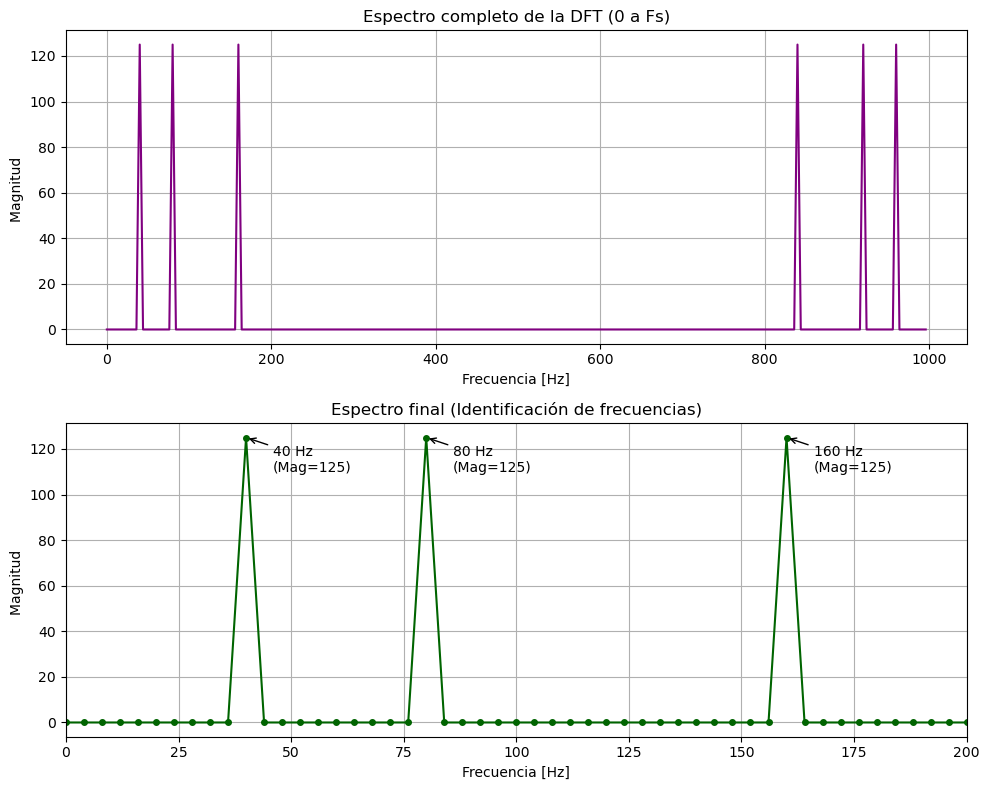

In [24]:
# Como en el punto anterior la señal se realizo con un periodo de 10 ahora iniciamos:
# Calculando la transformada de Fourier sobre los 10 periodos de la señal original ('signal') y
# y guardamos el resultado para conservar la señal del tiempo
signal_fft = np.fft.fft(signal)


N = len(signal_fft)                 # Número total de muestras 
print (N)
F = np.arange(0, N) * Fs / N   # para extraer las frecuencias en tiempo continuo: frecuencia F = (k * Fs) / N 


# Como la señal es real, la segunda mitad del espectro es un espejo de la primera.
# Nos quedamos solo con la primera mitad para analizarla con claridad.
N_mitad = int(np.ceil(N / 2))  # Punto medio del arreglo
print(N_mitad)
F_mitad = F[0:N_mitad]         # Frecuencias desde 0 Hz hasta Fs/2
signal_fft_mitad = signal_fft[0:N_mitad]     # Valores de la FFT correspondientes a esa mitad


# Graficamos la componente frecuencial de la señal 
plt.figure(figsize=(10, 8))

# Primero graficamos el espectro completo
plt.subplot(2, 1, 1)
plt.plot(F, np.abs(signal_fft), color='purple')       
plt.title("Espectro completo de la DFT (0 a Fs)")      
plt.xlabel("Frecuencia [Hz]")                          
plt.ylabel("Magnitud ")                          
plt.grid(True)                                        

# Luego graficamos el espectro hasta Nyquist con zoom 
plt.subplot(2, 1, 2)
plt.plot(F_mitad, np.abs(signal_fft_mitad), color='darkgreen', marker='o', markersize=4)
plt.title("Espectro final (Identificación de frecuencias)")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud ")
plt.xlim(0, 200)                                       
plt.grid(True)

# Recorremos las 3 frecuencias objetivo para señalar cada pico con una flecha
for freq_objetivo in [40, 80, 160]:
    idx = int(freq_objetivo * N / Fs)   # Calculamos en qué índice del arreglo cae esa frecuencia
    mag = np.abs(signal_fft_mitad[idx])          # Obtenemos la altura (magnitud) del pico en ese índice

    # Dibujamos la flecha y el texto sobre la gráfica activa (la #2)
    plt.annotate(
        f"{freq_objetivo} Hz\n(Mag={mag:.0f})",         
        xy=(freq_objetivo, mag),                        
        xytext=(freq_objetivo + 6, mag - 15),           
        arrowprops=dict(arrowstyle="->", color="black") 
    )

plt.tight_layout()
plt.show()

**4.3)** Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. 
Aplíquelo a la señal anterior.

- **Respuesta**

Error máximo de reconstrucción entre signal e ifft(fft(signal)): 1.11e-15


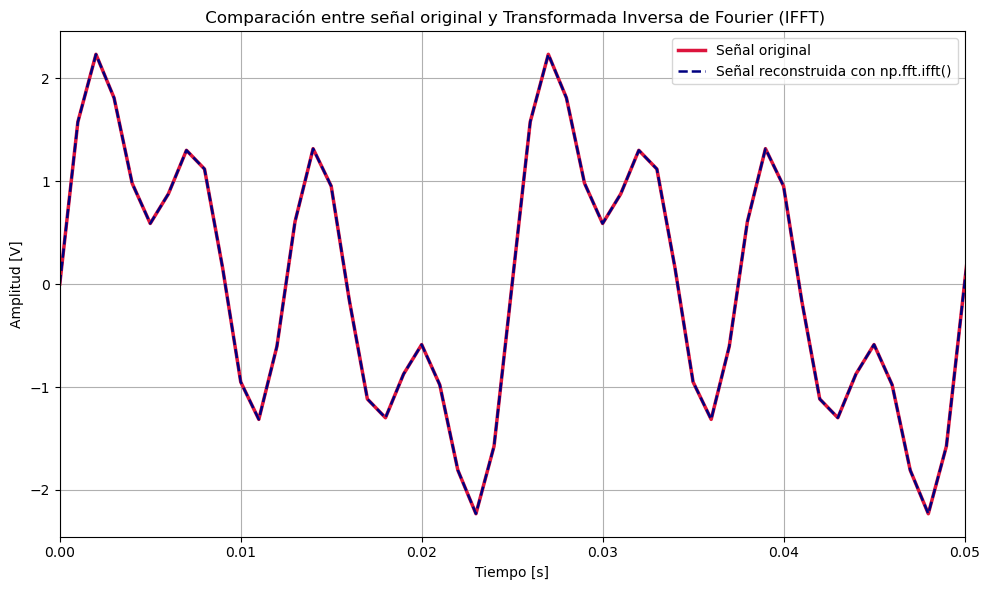

In [27]:
# La función en NumPy  para calcular la Transformada Discreta Inversa de Fourier
# es `np.fft.ifft()`. Esta permite reconstruir la señal en el dominio
# del tiempo a partir de sus coeficientes complejos en el dominio de la frecuencia. [1]

# Aplicamos la IFFT al espectro 'signal_fft' calculado en el numeral anterior
signal_reconstruida_compleja = np.fft.ifft(signal_fft)

# Luego extraemos la parte real con `np.real()` porque, debido a errores de redondeo de punto
# flotante (~1e-16j), la salida de `ifft` es de tipo complejo aunque la parte imaginaria sea nula.
signal_reconstruida = np.real(signal_reconstruida_compleja)

# Finalmente, verificamos numéricamente que el error máximo respecto a la señal original sea prácticamente cero
# Esto para corroborar que la señal construida a partir de este metodo si este correcta
error_maximo = np.max(np.abs(signal - signal_reconstruida))
print(f"Error máximo de reconstrucción entre signal e ifft(fft(signal)): {error_maximo:.2e}")

# Graficamos la señal original vs. la reconstruida mediante IFFT, para corroborar que se haya reconstruido fielmente
plt.figure(figsize=(10, 6))
plt.plot(t, signal, label="Señal original", color='crimson', linewidth=2.5)
plt.plot(t, signal_reconstruida, '--', label="Señal reconstruida con np.fft.ifft()", color='navy', linewidth=1.8)
plt.title(" Comparación entre señal original y Transformada Inversa de Fourier (IFFT)")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud [V]")
plt.xlim(0, 2 * Tp)   # Mostramos 2 periodos para comprobar la superposición exacta
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

- Se analiza que hay una alta similitud entre las señales, lo cual demuestra la buena reproducibilidad de la señal mediante el método de la trasnformada rapida de fourier

**4.4)** ¿Se Podría decir que las siguientes líneas aplican un filtro? ¿Por qué? 

F1 = np.fft.fft(x);

F2 = np.zeros((len(F1))); 

F2[9:13] = F1[9:13]; 

xr = np.fft.ifft(F2); 

fig = plt.figure() 

ax = fig.add_subplot(111) 

ax.plot(t, np.real(xr)) 

Introducción al análisis frecuencial de señales Bioseñales y sistemas 

ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)'); 

plt.show() 

Extraiga de manera similar cada una de las componentes de la señal.

- **Respuesta**


### *Referencias**
[1]	Mathworks.com. Consultado: el 22 de noviembre de 2026. [En línea]. Disponible en: https://la.mathworks.com/help/matlab/ref/ifft.html
